# EuroSAT — Pretrained Model Comparison

This notebook trains and compares several pretrained backbones (transfer learning, frozen weights) on the **EuroSAT** land-use/land-cover dataset:

- ConvNeXtTiny
- ResNet50
- EfficientNetB0
- MobileNetV2

Results are displayed in this form -
| Model | Test Accuracy | Macro F1 | Training Time |
|---|---|---|---|
| ConvNeXtTiny | | | |
| ResNet50 | | | |
| EfficientNetB0 | | | |
| MobileNetV2 | | | |


## 1. Imports

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import time
import zipfile
import cv2

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score
)

import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dropout, Dense
from tensorflow.keras.callbacks import EarlyStopping

from tensorflow.keras.applications import (
    ConvNeXtTiny,
    ResNet50,
    EfficientNetB0,
    MobileNetV2
)

from tensorflow.keras.applications.convnext import preprocess_input as convnext_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from tensorflow.keras.applications.efficientnet import preprocess_input as efficientnet_preprocess
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)


## 2. Download Dataset

In [ ]:
!mkdir -p ~/.kaggle
!cp "kaggle (1).json" ~/.kaggle/kaggle.json
!chmod 600 ~/.kaggle/kaggle.json

!kaggle datasets download apollo2506/eurosat-dataset


Dataset URL: https://www.kaggle.com/datasets/apollo2506/eurosat-dataset
License(s): CC0-1.0
100% 2.04G/2.04G [01:55<00:00, 19.0MB/s]



## 3. Extract Dataset

In [ ]:
zip_ref = zipfile.ZipFile('/content/eurosat-dataset.zip', 'r')
zip_ref.extractall('/content/')
zip_ref.close()


## 4. Dataset Path and Classes

In [ ]:
DATASET_PATH = "/content/EuroSAT"

classes = os.listdir(DATASET_PATH)

labels = [
    'AnnualCrop',
    'Forest',
    'HerbaceousVegetation',
    'Highway',
    'Industrial',
    'Pasture',
    'PermanentCrop',
    'Residential',
    'River',
    'SeaLake'
]

print("Classes:")
print(labels)


Classes:
['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


## 5. Load CSV Files

In [ ]:
train_df = pd.read_csv('/content/EuroSAT/train.csv')
test_df = pd.read_csv('/content/EuroSAT/test.csv')
val_df = pd.read_csv('/content/EuroSAT/validation.csv')

train_df = train_df.drop(columns=["Unnamed: 0"])
val_df = val_df.drop(columns=["Unnamed: 0"])
test_df = test_df.drop(columns=["Unnamed: 0"])

print("\nTraining Data:")
print(train_df.head())

print("\nValidation Data:")
print(val_df.head())

print("\nTesting Data:")
print(test_df.head())



Training Data:
                                            Filename  Label  \
0                      AnnualCrop/AnnualCrop_142.jpg      0   
1  HerbaceousVegetation/HerbaceousVegetation_2835...      2   
2               PermanentCrop/PermanentCrop_1073.jpg      6   
3                      Industrial/Industrial_453.jpg      4   
4  HerbaceousVegetation/HerbaceousVegetation_1810...      2   

              ClassName  
0            AnnualCrop  
1  HerbaceousVegetation  
2         PermanentCrop  
3            Industrial  
4  HerbaceousVegetation  

Validation Data:
                   Filename  Label ClassName
0  Pasture/Pasture_1481.jpg      5   Pasture
1    Forest/Forest_2638.jpg      1    Forest
2   Highway/Highway_875.jpg      3   Highway
3       River/River_434.jpg      8     River
4  SeaLake/SeaLake_2930.jpg      9   SeaLake

Testing Data:
                           Filename  Label    ClassName
0    AnnualCrop/AnnualCrop_1275.jpg      0   AnnualCrop
1   Residential/Residential_504.jp

## 6. Load Images

A single reusable function replaces the three near-identical loops from the original script (one for train, one for val, one for test). Images are kept as raw `uint8` RGB arrays here — each model's own `preprocess_input` is applied later, right before that model is trained, since different backbones expect different normalization.

In [ ]:
def load_images(df, dataset_path):
    X, y = [], []
    for _, row in df.iterrows():
        image_path = os.path.join(dataset_path, row['Filename'])
        img = cv2.imread(image_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        X.append(img)
        y.append(row['Label'])
    return np.array(X), np.array(y)


X_train, y_train = load_images(train_df, DATASET_PATH)
X_val, y_val = load_images(val_df, DATASET_PATH)
X_test, y_test = load_images(test_df, DATASET_PATH)

print("\nTraining Shape:", X_train.shape, y_train.shape)
print("Validation Shape:", X_val.shape, y_val.shape)
print("Testing Shape:", X_test.shape, y_test.shape)



Training Shape: (18900, 64, 64, 3) (18900,)
Validation Shape: (5400, 64, 64, 3) (5400,)
Testing Shape: (2700, 64, 64, 3) (2700,)


## 7. Visualize Class Distribution & Sample Image

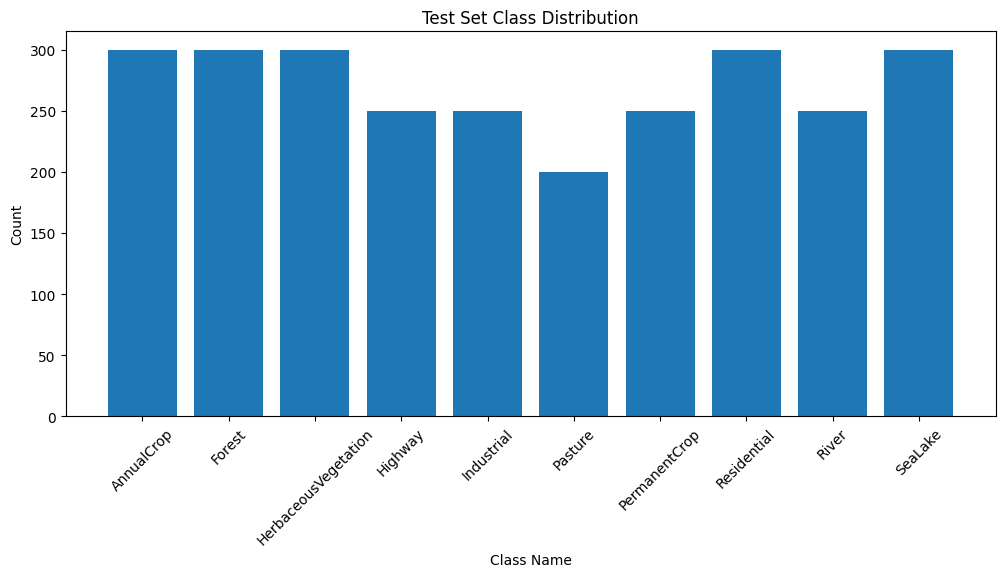

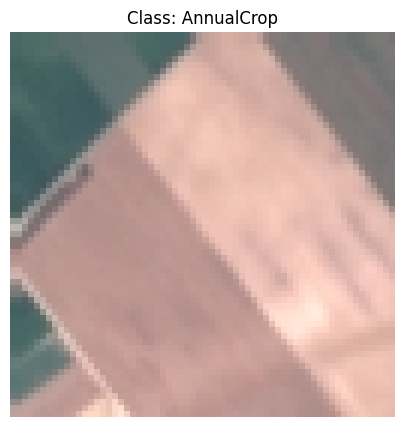

In [ ]:
class_counts = test_df["ClassName"].value_counts().sort_index()

plt.figure(figsize=(12, 5))
plt.bar(class_counts.index, class_counts.values)
plt.xlabel("Class Name")
plt.ylabel("Count")
plt.title("Test Set Class Distribution")
plt.xticks(rotation=45)
plt.show()

plt.figure(figsize=(5, 5))
plt.imshow(X_train[0])
plt.title("Class: " + labels[y_train[0]])
plt.axis("off")
plt.show()


## 8. Model Comparison Pipeline

`MODEL_CONFIGS` maps a model name to its Keras Applications class and its matching `preprocess_input` function. Add or remove an entry here to change which backbones get compared — everything downstream (training, metrics, plots, table) loops over this dict automatically.

In [ ]:
MODEL_CONFIGS = {
    "ConvNeXtTiny": {"class": ConvNeXtTiny, "preprocess": convnext_preprocess},
    "ResNet50": {"class": ResNet50, "preprocess": resnet_preprocess},
    "EfficientNetB0": {"class": EfficientNetB0, "preprocess": efficientnet_preprocess},
    "MobileNetV2": {"class": MobileNetV2, "preprocess": mobilenet_preprocess},
}

INPUT_SHAPE = X_train.shape[1:]   # (64, 64, 3)
NUM_CLASSES = 10
EPOCHS = 30
BATCH_SIZE = 32

print("Models to compare:", list(MODEL_CONFIGS.keys()))
print("Input shape:", INPUT_SHAPE)


Models to compare: ['ConvNeXtTiny', 'ResNet50', 'EfficientNetB0', 'MobileNetV2']
Input shape: (64, 64, 3)


### 8.1 Build / Train / Evaluate helpers

In [ ]:
def build_model(base_class, input_shape=INPUT_SHAPE, num_classes=NUM_CLASSES):
    base_model = base_class(
        weights="imagenet",
        include_top=False,
        input_shape=input_shape
    )

    # Freeze pretrained layers
    base_model.trainable = False

    model = Sequential([
        base_model,
        GlobalAveragePooling2D(),
        Dropout(0.2),
        Dense(num_classes, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


def train_and_evaluate(name, config,
                        X_train, y_train,
                        X_val, y_val,
                        X_test, y_test,
                        labels,
                        epochs=EPOCHS,
                        batch_size=BATCH_SIZE):

    print("\n" + "=" * 60)
    print("TRAINING:", name)
    print("=" * 60)

    preprocess = config["preprocess"]

    # Each backbone gets its own correct normalization, applied to a
    # float32 copy of the raw uint8 images.
    Xtr = preprocess(X_train.astype("float32").copy())
    Xv = preprocess(X_val.astype("float32").copy())
    Xte = preprocess(X_test.astype("float32").copy())

    model = build_model(config["class"])

    callback = EarlyStopping(
        monitor="val_loss",
        patience=5,
        verbose=1,
        min_delta=0.001,
        mode="auto",
        restore_best_weights=True
    )

    # Wall-clock training time, so accuracy can be weighed against
    # computational cost (useful when comparing e.g. MobileNetV2
    # against much larger backbones).
    start_time = time.time()

    history = model.fit(
        Xtr, y_train,
        validation_data=(Xv, y_val),
        epochs=epochs,
        batch_size=batch_size,
        callbacks=[callback],
        verbose=1
    )

    training_time_sec = time.time() - start_time

    best_val_accuracy = max(history.history["val_accuracy"])
    best_val_loss = min(history.history["val_loss"])

    test_loss, test_accuracy = model.evaluate(Xte, y_test, verbose=0)

    predictions = model.predict(Xte, verbose=0)
    y_pred = np.argmax(predictions, axis=1)

    macro_precision = precision_score(y_test, y_pred, average="macro")
    macro_recall = recall_score(y_test, y_pred, average="macro")
    macro_f1 = f1_score(y_test, y_pred, average="macro")
    weighted_f1 = f1_score(y_test, y_pred, average="weighted")

    cm = confusion_matrix(y_test, y_pred)
    report_str = classification_report(y_test, y_pred, target_names=labels)

    print("\nTest Accuracy:", test_accuracy, "| Macro F1:", macro_f1)
    print("Training Time: {:.1f}s ({:.2f} min)".format(training_time_sec, training_time_sec / 60))

    return {
        "name": name,
        "model": model,
        "history": history,
        "test_accuracy": test_accuracy,
        "test_loss": test_loss,
        "best_val_accuracy": best_val_accuracy,
        "best_val_loss": best_val_loss,
        "macro_precision": macro_precision,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1,
        "weighted_f1": weighted_f1,
        "training_time_sec": training_time_sec,
        "confusion_matrix": cm,
        "classification_report": report_str,
        "y_pred": y_pred,
    }


### 8.2 Run the comparison

Trains every model in `MODEL_CONFIGS` and stores each result.

In [ ]:
results = {}

for name, config in MODEL_CONFIGS.items():
    results[name] = train_and_evaluate(
        name, config,
        X_train, y_train,
        X_val, y_val,
        X_test, y_test,
        labels
    )



TRAINING: ConvNeXtTiny
111650432/111650432 ━━━━━━━━━━━━━━━━━━━━ 7s 0us/step
Epoch 1/30
591/591 ━━━━━━━━━━━━━━━━━━━━ 40s 41ms/step - accuracy: 0.8079 - loss: 0.5968 - val_accuracy: 0.9056 - val_loss: 0.2958
Epoch 2/30
591/591 ━━━━━━━━━━━━━━━━━━━━ 9s 16ms/step - accuracy: 0.9149 - loss: 0.2633 - val_accuracy: 0.9193 - val_loss: 0.2414
Epoch 3/30
591/591 ━━━━━━━━━━━━━━━━━━━━ 9s 16ms/step - accuracy: 0.9313 - loss: 0.2162 - val_accuracy: 0.9257 - val_loss: 0.2205
Epoch 4/30
591/591 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.9371 - loss: 0.1927 - val_accuracy: 0.9291 - val_loss: 0.2091
Epoch 5/30
591/591 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.9403 - loss: 0.1776 - val_accuracy: 0.9330 - val_loss: 0.2005
Epoch 6/30
591/591 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.9448 - loss: 0.1678 - val_accuracy: 0.9331 - val_loss: 0.1963
Epoch 7/30
591/591 ━━━━━━━━━━━━━━━━━━━━ 10s 17ms/step - accuracy: 0.9466 - loss: 0.1594 - val_accuracy: 0.9348 - val_loss: 0.1935
Epoch 8/30
591/

/tmp/ipykernel_2385/1551474396.py:2: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = base_class(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/30
591/591 ━━━━━━━━━━━━━━━━━━━━ 42s 48ms/step - accuracy: 0.7561 - loss: 0.7551 - val_accuracy: 0.8487 - val_loss: 0.4680
Epoch 2/30
591/591 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.8553 - loss: 0.4460 - val_accuracy: 0.8613 - val_loss: 0.4310
Epoch 3/30
591/591 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - accuracy: 0.8737 - loss: 0.3841 - val_accuracy: 0.8654 - val_loss: 0.4164
Epoch 4/30
591/591 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.8811 - loss: 0.3556 - val_accuracy: 0.8693 - val_loss: 0.4163
Epoch 5/30
591/591 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.8867 - loss: 0.3389 - val_accuracy: 0.8700 - val_loss: 0.4227
Epoch 6/30
591/591 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.8923 - loss: 0.3222 - val_accuracy: 0.8657 - val_loss: 0.4256
Epoch 7/30
591/591 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.8921 - loss: 0.3179 - val_accuracy: 0.8643 - val_loss: 0.4309
Epoch 8/30
591/591 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/st

## 9. Results Comparison Table

In [ ]:
comparison_df = pd.DataFrame([
    {
        "Model": r["name"],
        "Test Accuracy": r["test_accuracy"],
        "Macro F1": r["macro_f1"],
        "Best Val Accuracy": r["best_val_accuracy"],
        "Macro Precision": r["macro_precision"],
        "Macro Recall": r["macro_recall"],
        "Weighted F1": r["weighted_f1"],
        "Test Loss": r["test_loss"],
        "Training Time (s)": r["training_time_sec"],
    }
    for r in results.values()
]).sort_values("Test Accuracy", ascending=False).reset_index(drop=True)

comparison_df["Training Time (min)"] = (comparison_df["Training Time (s)"] / 60).round(2)

# Percentage view for quick reading (the core table the project asked for)
summary_table = comparison_df[["Model", "Test Accuracy", "Macro F1", "Training Time (min)"]].copy()
summary_table["Test Accuracy"] = (summary_table["Test Accuracy"] * 100).round(2)
summary_table["Macro F1"] = (summary_table["Macro F1"] * 100).round(2)

summary_table


,Model,Test Accuracy,Macro F1,Training Time (min)
0,ConvNeXtTiny,94.33,94.04,3.11
1,EfficientNetB0,93.15,92.92,3.12
2,ResNet50,92.19,91.81,1.80
3,MobileNetV2,89.04,88.56,1.46


## 10. Visual Comparison

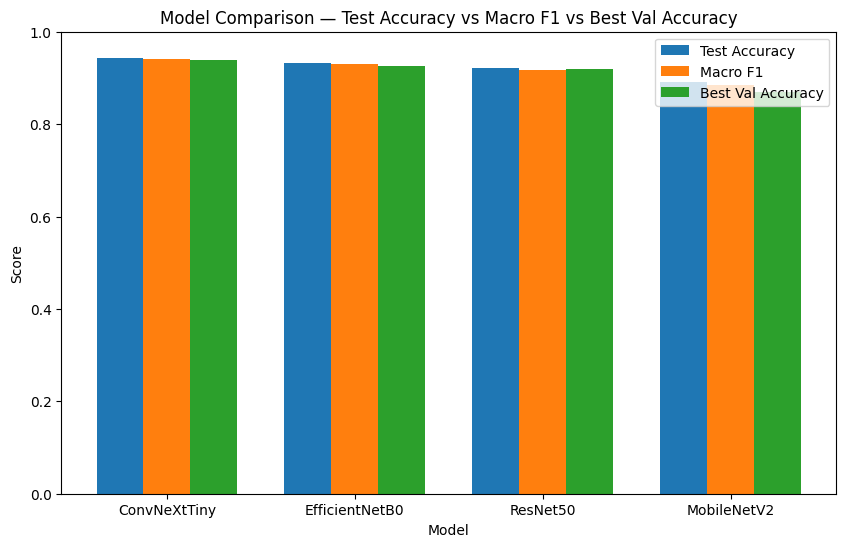

In [ ]:
metrics_to_plot = ["Test Accuracy", "Macro F1", "Best Val Accuracy"]

x = np.arange(len(comparison_df))
width = 0.25

plt.figure(figsize=(10, 6))

for i, metric in enumerate(metrics_to_plot):
    plt.bar(x + i * width, comparison_df[metric], width, label=metric)

plt.xlabel("Model")
plt.ylabel("Score")
plt.title("Model Comparison — Test Accuracy vs Macro F1 vs Best Val Accuracy")
plt.xticks(x + width, comparison_df["Model"])
plt.ylim(0, 1)
plt.legend()
plt.show()


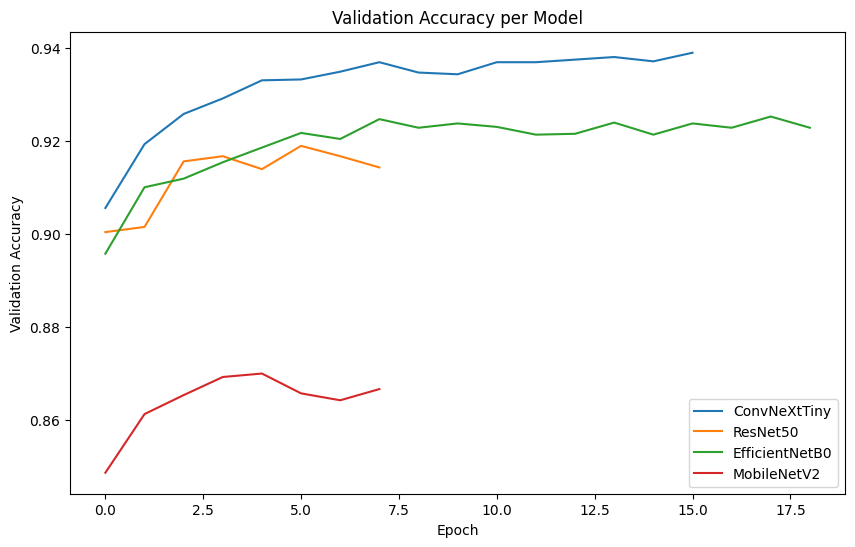

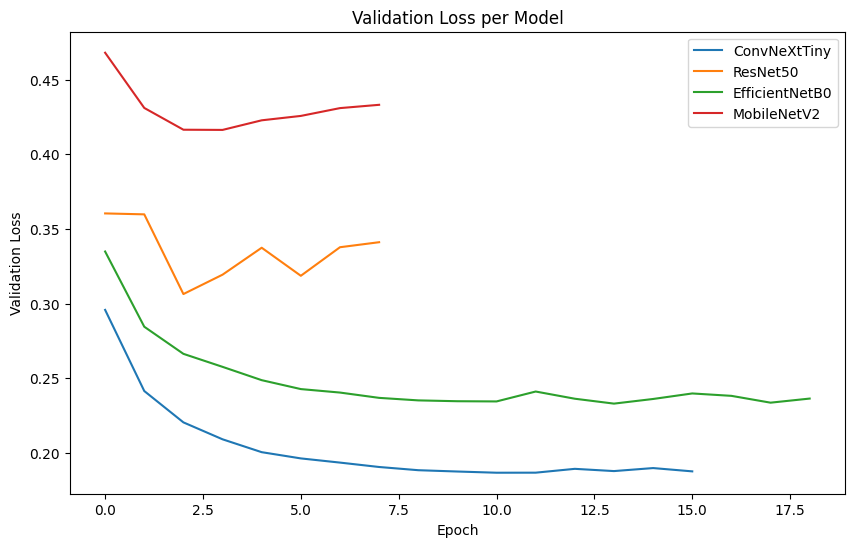

In [ ]:
# Training curves for every model
plt.figure(figsize=(10, 6))
for name, r in results.items():
    plt.plot(r["history"].history["val_accuracy"], label=name)
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Validation Accuracy per Model")
plt.legend()
plt.show()

plt.figure(figsize=(10, 6))
for name, r in results.items():
    plt.plot(r["history"].history["val_loss"], label=name)
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Validation Loss per Model")
plt.legend()
plt.show()


## 11. Per-Model Confusion Matrices

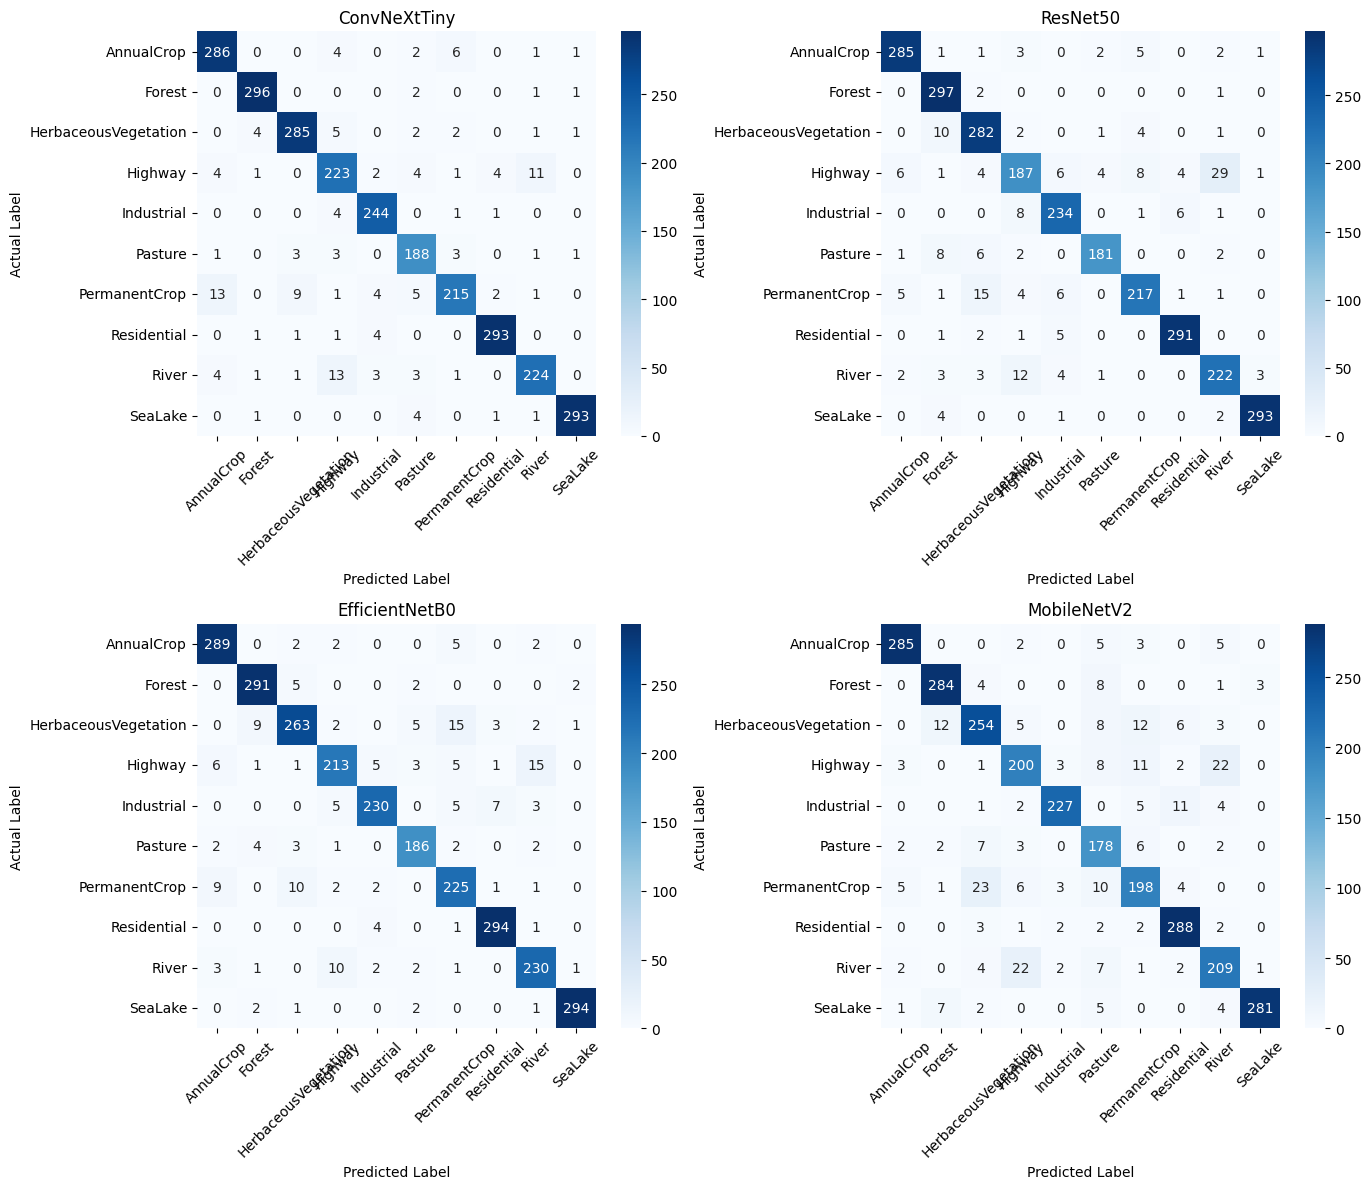

In [ ]:
n_models = len(results)
n_cols = 2
n_rows = int(np.ceil(n_models / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 6 * n_rows))
axes = np.array(axes).reshape(-1)

for ax, (name, r) in zip(axes, results.items()):
    sns.heatmap(
        r["confusion_matrix"],
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=labels,
        yticklabels=labels,
        ax=ax
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")
    ax.tick_params(axis='x', rotation=45)
    ax.tick_params(axis='y', rotation=0)

for ax in axes[n_models:]:
    ax.axis("off")

plt.tight_layout()
plt.show()


## 12. Save All Models and Results

Every trained model is saved, not just the top scorer

In [ ]:
for name, r in results.items():
    filename = f"eurosat_{name.lower()}.keras"
    r["model"].save(filename)
    print("Saved:", filename)

comparison_df.to_csv("eurosat_model_comparison.csv", index=False)
print("Saved comparison table: eurosat_model_comparison.csv")

top_name = comparison_df.iloc[0]["Model"]
top_accuracy = comparison_df.iloc[0]["Test Accuracy"]
print(
    "\nThe model with the highest test accuracy in this experiment was "
    f"{top_name} ({top_accuracy * 100:.2f}%) — this reflects performance "
    "under this specific setup (frozen weights, this dataset split, these "
    "training settings), not a universal ranking of the architectures."
)

comparison_df


Saved: eurosat_convnexttiny.keras
Saved: eurosat_resnet50.keras
Saved: eurosat_efficientnetb0.keras
Saved: eurosat_mobilenetv2.keras
Saved comparison table: eurosat_model_comparison.csv

The model with the highest test accuracy in this experiment was ConvNeXtTiny (94.33%) — this reflects performance under this specific setup (frozen weights, this dataset split, these training settings), not a universal ranking of the architectures.


,Model,Test Accuracy,Macro F1,Best Val Accuracy,Macro Precision,Macro Recall,Weighted F1,Test Loss,Training Time (s),Training Time (min)
0,ConvNeXtTiny,0.943333,0.940377,0.938889,0.940632,0.940733,0.943165,0.163188,186.740677,3.11
1,EfficientNetB0,0.931481,0.929185,0.925185,0.929680,0.929200,0.931265,0.200507,187.368261,3.12
2,ResNet50,0.921852,0.918092,0.918889,0.920585,0.917167,0.921078,0.273232,107.824662,1.80
3,MobileNetV2,0.890370,0.885591,0.870000,0.885961,0.886600,0.890601,0.366773,87.554371,1.46
